Mount Drive and check the files

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/DS_Sprint_CH28'
RAW, CLEAN, OUT = f'{BASE}/data/raw', f'{BASE}/data/clean', f'{BASE}/outputs'

# make sure the output folders exist
for p in (CLEAN, OUT):
    os.makedirs(p, exist_ok=True)

print(os.listdir(RAW))

Mounted at /content/drive
['releases.csv', 'metrics.csv', 'commits.csv', 'defects.csv', 'modules.csv']


Load all 5 files

In [2]:
import pandas as pd

modules  = pd.read_csv(f'{RAW}/modules.csv')
metrics  = pd.read_csv(f'{RAW}/metrics.csv')
defects  = pd.read_csv(f'{RAW}/defects.csv')
commits  = pd.read_csv(f'{RAW}/commits.csv')
releases = pd.read_csv(f'{RAW}/releases.csv')

for name, df in [('modules', modules), ('metrics', metrics), ('defects', defects),
                 ('commits', commits), ('releases', releases)]:
    print(name, df.shape)

modules (47, 5)
metrics (249, 6)
defects (216, 5)
commits (235, 5)
releases (247, 4)


# Phase 1: The Audit

Cell 1: Structure and data types

In [3]:
for name, df in [('modules', modules), ('metrics', metrics), ('defects', defects),
                 ('commits', commits), ('releases', releases)]:
    print(f'\n===== {name} {df.shape} =====')
    print(df.dtypes)
    display(df.head(3))


===== modules (47, 5) =====
module_id    object
module       object
component    object
language     object
size          int64
dtype: object


,module_id,module,component,language,size
0,M001,auth_login,Auth,Java,1070
1,M002,auth_session,Auth,Python,3134
2,M003,auth_oauth,Auth,Java,619



===== metrics (249, 6) =====
module            object
release           object
complexity       float64
coupling         float64
churn            float64
test_coverage    float64
dtype: object


,module,release,complexity,coupling,churn,test_coverage
0,database_backup,v2.0,10.47,8.33,192.0,67.7
1,auth_session,v1.1,26.79,21.88,612.5,24.9
2,ui_charts,v2.0,14.33,8.30,348.9,NaN



===== defects (216, 5) =====
defect_id       object
module          object
release         object
defect_count     int64
severity        object
dtype: object


,defect_id,module,release,defect_count,severity
0,D0001,payments_crypto,v1.0,1,Medium
1,D0002,payments_crypto,v1.0,2,High
2,D0003,api_gateway,v1.1,1,Medium



===== commits (235, 5) =====
module            object
release           object
commit_count       int64
contributors     float64
changed_lines      int64
dtype: object


,module,release,commit_count,contributors,changed_lines
0,AUTH_LOGIN,v1.0,7,3.0,233
1,Auth_Login,v1.1,16,5.0,502
2,auth_login,v2.0,1,1.0,97



===== releases (247, 4) =====
release_id      object
version         object
release_date    object
module          object
dtype: object


,release_id,version,release_date,module
0,R0034,v2.1,2025-02-18,auth-rbac
1,R0007,v1.1,2024-05-20,auth_session
2,R0182,v1.1,2024-05-20,api_graphql


Cell 2: Missing values and exact duplicates

In [4]:
audit = []
for name, df in [('modules', modules), ('metrics', metrics), ('defects', defects),
                 ('commits', commits), ('releases', releases)]:
    audit.append({'file': name, 'rows': len(df),
                  'missing_cells': int(df.isna().sum().sum()),
                  'exact_duplicate_rows': int(df.duplicated().sum())})
display(pd.DataFrame(audit))

print('\nMissing values per column:')
print('metrics:\n', metrics.isna().sum())
print('commits:\n', commits.isna().sum())

,file,rows,missing_cells,exact_duplicate_rows
0,modules,47,0,0
1,metrics,249,58,14
2,defects,216,0,0
3,commits,235,7,0
4,releases,247,0,12



Missing values per column:
metrics:
 module            0
release           0
complexity       14
coupling         15
churn            15
test_coverage    14
dtype: int64
commits:
 module           0
release          0
commit_count     0
contributors     7
changed_lines    0
dtype: int64


Cell 3: Inconsistent module names

In [5]:
def norm(s):
    return s.str.strip().str.lower().str.replace('-', '_')

official = set(modules['module'])

for name, df in [('metrics', metrics), ('defects', defects),
                 ('commits', commits), ('releases', releases)]:
    raw_names = df['module'].unique()
    fixed = set(norm(pd.Series(raw_names)))
    print(f'{name}: {len(raw_names)} distinct raw names -> {len(fixed)} after normalizing; '
          f'{len(fixed - official)} not in modules.csv')

print('\nExample variants of one module:')
print([n for n in metrics['module'].unique() if 'auth_login' in n.lower().replace('-', '_')])

metrics: 102 distinct raw names -> 47 after normalizing; 0 not in modules.csv
defects: 94 distinct raw names -> 46 after normalizing; 5 not in modules.csv
commits: 96 distinct raw names -> 47 after normalizing; 0 not in modules.csv
releases: 106 distinct raw names -> 47 after normalizing; 0 not in modules.csv

Example variants of one module:
['auth_login']


Cell 4: Extreme complexity values

count    235.000000
mean      23.450681
std       46.999762
min        2.000000
25%       10.450000
50%       15.060000
75%       19.490000
max      299.870000
Name: complexity, dtype: float64


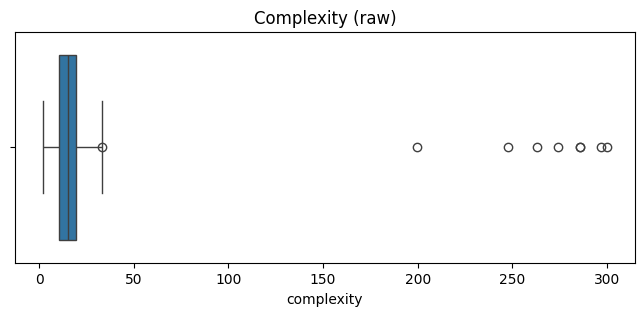

IQR upper fence: 33.1
Rows above fence: 9


,module,release,complexity,coupling,churn,test_coverage
212,payments_gateway,v2.1,299.87,12.51,66.3,60.0
127,ui_charts,v2.1,296.70,13.47,604.9,57.9
20,payments_gateway,v1.0,285.79,12.80,212.6,56.5
26,payments_gateway,v1.0,285.79,12.80,212.6,56.5
94,payments_checkout,v2.0,274.00,10.84,52.1,52.6
213,PAYMENTS_INVOICE,v2.1,262.98,12.12,323.6,58.1
139,database_indexing,v2.1,247.73,9.97,369.8,60.3
202,ui_search,v2.0,199.48,10.03,384.0,59.1
163,reporting_scheduler,v3.0,33.40,NaN,262.5,NaN


In [6]:
print(metrics['complexity'].describe())

import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 3))
sns.boxplot(x=metrics['complexity'])
plt.title('Complexity (raw)')
plt.show()

Q1, Q3 = metrics['complexity'].quantile([0.25, 0.75])
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
print(f'IQR upper fence: {upper:.1f}')
print('Rows above fence:', (metrics['complexity'] > upper).sum())
display(metrics[metrics['complexity'] > upper].sort_values('complexity', ascending=False))

Cell 5: Unmatched defect records

In [7]:
d = defects.copy()
d['module_clean'] = norm(d['module'])
unmatched = d[~d['module_clean'].isin(official)]
print('Unmatched defect rows:', len(unmatched))
print('Defects in those rows:', unmatched['defect_count'].sum())
print(unmatched['module_clean'].value_counts())

Unmatched defect rows: 18
Defects in those rows: 53
module_clean
payments_crypto    6
ui_widgets_old     4
auth_sso_beta      3
tmp_migration      3
reporting_v0       2
Name: count, dtype: int64


Cell 6: Duplicate module-release keys (after name cleanup)

In [8]:
m = metrics.copy()
m['module'] = norm(m['module'])
print('metrics duplicate module-release keys:', m.duplicated(subset=['module', 'release']).sum())

r = releases.copy()
r['module'] = norm(r['module'])
print('releases duplicate module-release keys:', r.duplicated(subset=['module', 'version']).sum())

metrics duplicate module-release keys: 14
releases duplicate module-release keys: 12


# Phase 2: Clean

Cell 1: Standardize module names

In [9]:
def norm(s):
    return s.str.strip().str.lower().str.replace('-', '_')

metrics_c  = metrics.copy();  metrics_c['module']  = norm(metrics_c['module'])
defects_c  = defects.copy();  defects_c['module']  = norm(defects_c['module'])
commits_c  = commits.copy();  commits_c['module']  = norm(commits_c['module'])
releases_c = releases.copy(); releases_c['module'] = norm(releases_c['module'])
releases_c = releases_c.rename(columns={'version': 'release'})   # same key name everywhere

print('metrics names:', metrics_c['module'].nunique(), '| commits:', commits_c['module'].nunique(),
      '| releases:', releases_c['module'].nunique())

metrics names: 47 | commits: 47 | releases: 47


Cell 2: Remove duplicates and check keys

In [10]:
before = {'metrics': len(metrics_c), 'releases': len(releases_c)}
metrics_c  = metrics_c.drop_duplicates()
releases_c = releases_c.drop_duplicates()
print('metrics rows:', before['metrics'], '->', len(metrics_c))
print('releases rows:', before['releases'], '->', len(releases_c))

for name, df in [('metrics', metrics_c), ('commits', commits_c), ('releases', releases_c)]:
    print(name, 'duplicate module-release keys:', df.duplicated(subset=['module', 'release']).sum())

metrics rows: 249 -> 235
releases rows: 247 -> 235
metrics duplicate module-release keys: 0
commits duplicate module-release keys: 0
releases duplicate module-release keys: 0


Cell 3: Separate the unmatched defects

In [11]:
official = set(modules['module'])
orphan_defects = defects_c[~defects_c['module'].isin(official)].copy()
defects_c = defects_c[defects_c['module'].isin(official)].copy()
print('orphan rows set aside:', len(orphan_defects), '| defects in them:', orphan_defects['defect_count'].sum())
print('defect rows kept:', len(defects_c))

orphan rows set aside: 18 | defects in them: 53
defect rows kept: 198


Cell 4: Handle extreme complexity

In [12]:
metrics_c['complexity_raw'] = metrics_c['complexity']
metrics_c['complexity_outlier'] = metrics_c['complexity'] > 100
print('extreme values flagged:', metrics_c['complexity_outlier'].sum())
metrics_c.loc[metrics_c['complexity_outlier'], 'complexity'] = float('nan')

extreme values flagged: 7


Cell 5: Fill missing values

In [13]:
num_cols = ['complexity', 'coupling', 'churn', 'test_coverage']
print('missing before:\n', metrics_c[num_cols].isna().sum())

for col in num_cols:
    metrics_c[col] = metrics_c[col].fillna(metrics_c.groupby('module')[col].transform('median'))
    metrics_c[col] = metrics_c[col].fillna(metrics_c[col].median())   # safety net

# contributors: median of the same module
commits_c['contributors'] = commits_c['contributors'].fillna(
    commits_c.groupby('module')['contributors'].transform('median')).round()

print('\nmissing after:\n', metrics_c[num_cols].isna().sum())
print('commits missing after:', commits_c['contributors'].isna().sum())
print(metrics_c['complexity'].describe())

missing before:
 complexity       21
coupling         14
churn            14
test_coverage    14
dtype: int64

missing after:
 complexity       0
coupling         0
churn            0
test_coverage    0
dtype: int64
commits missing after: 0
count    235.000000
mean      15.072255
std        6.676008
min        2.000000
25%       10.450000
50%       14.960000
75%       19.532500
max       33.400000
Name: complexity, dtype: float64


Cell 6: Save the cleaned files

In [14]:
metrics_c.to_csv(f'{CLEAN}/metrics_clean.csv', index=False)
defects_c.to_csv(f'{CLEAN}/defects_clean.csv', index=False)
orphan_defects.to_csv(f'{CLEAN}/defects_orphans.csv', index=False)
commits_c.to_csv(f'{CLEAN}/commits_clean.csv', index=False)
releases_c.to_csv(f'{CLEAN}/releases_clean.csv', index=False)
print('saved to', CLEAN)

saved to /content/drive/MyDrive/DS_Sprint_CH28/data/clean


# Phase 3: Merge and feature engineering

Cell 1: Aggregate defects to module-release level

In [15]:
sev = defects_c.pivot_table(index=['module', 'release'], columns='severity',
                            values='defect_count', aggfunc='sum', fill_value=0).reset_index()
sev = sev.rename(columns={'Low': 'defects_low', 'Medium': 'defects_medium',
                          'High': 'defects_high', 'Critical': 'defects_critical'})
for c in ['defects_low', 'defects_medium', 'defects_high', 'defects_critical']:
    if c not in sev.columns:
        sev[c] = 0
sev['total_defects'] = sev[['defects_low', 'defects_medium', 'defects_high', 'defects_critical']].sum(axis=1)
print(sev.shape)
print('total defects:', sev['total_defects'].sum(), '| should equal', defects_c['defect_count'].sum())

(120, 7)
total defects: 285 | should equal 285


Cell 2: Merge everything (one row per module-release)

In [16]:
df = (releases_c[['module', 'release', 'release_date']]
      .merge(modules[['module', 'component', 'language', 'size']], on='module', how='left', validate='many_to_one')
      .merge(metrics_c[['module', 'release', 'complexity', 'complexity_raw', 'complexity_outlier',
                        'coupling', 'churn', 'test_coverage']],
             on=['module', 'release'], how='left', validate='one_to_one')
      .merge(commits_c[['module', 'release', 'commit_count', 'contributors', 'changed_lines']],
             on=['module', 'release'], how='left', validate='one_to_one')
      .merge(sev, on=['module', 'release'], how='left', validate='one_to_one'))

defect_cols = ['defects_low', 'defects_medium', 'defects_high', 'defects_critical', 'total_defects']
df[defect_cols] = df[defect_cols].fillna(0).astype(int)

assert len(df) == 235 and df['module'].nunique() == 47 and df['release'].nunique() == 5
assert df['total_defects'].sum() == defects_c['defect_count'].sum()
print(df.shape)
print('missing cells:', int(df.isna().sum().sum()))
zero_mods = df.groupby('module')['total_defects'].sum()
print('modules with zero defects in every release:', int((zero_mods == 0).sum()))

(235, 20)
missing cells: 14
modules with zero defects in every release: 6


Cell 3: Engineered features

In [20]:
import numpy as np

df['release_date'] = pd.to_datetime(df['release_date'])
order = {r: i + 1 for i, r in enumerate(sorted(df['release'].unique(),
         key=lambda r: df.loc[df['release'] == r, 'release_date'].iloc[0]))}
df['release_index'] = df['release'].map(order)
df = df.sort_values(['module', 'release_index']).reset_index(drop=True)

# ratios from the metrics
df['churn_per_commit']        = df['churn'] / df['commit_count']
df['lines_per_contributor']   = df['changed_lines'] / df['contributors']
df['commits_per_contributor'] = df['commit_count'] / df['contributors']

# defect-based features (for EDA and the pitch, NOT for the ML model)
df['defect_density']        = df['total_defects'] / df['size'] * 1000      # defects per 1,000 lines
df['high_severity_defects'] = df['defects_high'] + df['defects_critical']
df['high_severity_ratio']   = np.where(df['total_defects'] > 0,
                                       df['high_severity_defects'] / df['total_defects'], 0)
df['weighted_severity']     = (df['defects_low'] + 2 * df['defects_medium']
                               + 3 * df['defects_high'] + 4 * df['defects_critical'])

# history and repeat-defect features
df['defects_prev_release'] = df.groupby('module')['total_defects'].shift(1).fillna(0).astype(int)
releases_with_defects = df.groupby('module')['total_defects'].transform(lambda s: (s > 0).sum())
df['repeat_defect_flag'] = (releases_with_defects >= 2).astype(int)

# risk score (0-100): equal-weight mix of churn, complexity and LOW coverage; built only from metrics
def minmax(s): return (s - s.min()) / (s.max() - s.min())
df['risk_score'] = 100 * (minmax(df['churn']) + minmax(df['complexity']) + (1 - minmax(df['test_coverage']))) / 3

# binary target for a classification view
threshold = df['total_defects'].quantile(0.75)
df['high_defect'] = (df['total_defects'] > threshold).astype(int)
print('75th percentile threshold:', threshold)
print(df['high_defect'].value_counts())

75th percentile threshold: 2.0
high_defect
0    199
1     36
Name: count, dtype: int64


Cell 4: Encode categorical variables

In [21]:
df = pd.get_dummies(df, columns=['component', 'language'], prefix=['comp', 'lang'], dtype=int)
# (the original text columns are dropped by get_dummies; we re-add them below for EDA and Excel)
df['component'] = df[[c for c in df.columns if c.startswith('comp_')]].idxmax(axis=1).str.replace('comp_', '')
df['language']  = df[[c for c in df.columns if c.startswith('lang_')]].idxmax(axis=1).str.replace('lang_', '')
print(df.shape)
print([c for c in df.columns if c.startswith(('comp_', 'lang_'))])

(235, 42)
['comp_API', 'comp_Auth', 'comp_Database', 'comp_Payments', 'comp_Reporting', 'comp_UI', 'lang_C++', 'lang_Java', 'lang_JavaScript', 'lang_Python']


(235, 42)
['comp_API', 'comp_Auth', 'comp_Database', 'comp_Payments', 'comp_Reporting', 'comp_UI', 'lang_C++', 'lang_Java', 'lang_JavaScript', 'lang_Python']


Cell 5: Module-level summary (one row per module)

In [22]:
module_summary = df.groupby('module').agg(
    component=('component', 'first'), language=('language', 'first'), size=('size', 'first'),
    avg_complexity=('complexity', 'mean'), avg_churn=('churn', 'mean'),
    avg_coverage=('test_coverage', 'mean'), avg_contributors=('contributors', 'mean'),
    total_defects=('total_defects', 'sum'), max_defects_in_a_release=('total_defects', 'max'),
    releases_with_defects=('total_defects', lambda s: (s > 0).sum()),
    high_severity_defects=('high_severity_defects', 'sum'), avg_risk_score=('risk_score', 'mean')
).reset_index().sort_values('total_defects', ascending=False)
module_summary['defect_density'] = module_summary['total_defects'] / module_summary['size'] * 1000
display(module_summary.head(10).round(2))

,module,component,language,size,avg_complexity,avg_churn,avg_coverage,avg_contributors,total_defects,max_defects_in_a_release,releases_with_defects,high_severity_defects,avg_risk_score,defect_density
1,api_gateway,API,Java,2296,19.60,513.16,41.04,4.4,29,15,5,8,57.80,12.63
43,ui_notifications,UI,JavaScript,7222,12.63,808.79,33.14,5.2,25,10,4,7,62.11,3.46
46,ui_themes,UI,JavaScript,2559,31.17,392.48,55.52,3.2,19,10,4,6,60.18,7.42
14,auth_session,Auth,Python,3134,20.78,481.88,36.74,4.4,17,8,5,1,60.16,5.42
24,payments_fraud,Payments,Java,1821,19.56,520.96,37.76,4.0,15,9,4,1,59.47,8.24
33,reporting_audit_logs,Reporting,Java,3061,22.64,559.24,63.26,4.6,14,5,5,4,52.16,4.57
37,reporting_scheduler,Reporting,Java,1361,27.75,262.51,41.03,4.0,13,4,5,4,59.59,9.55
19,database_migration,Database,C++,2891,18.59,496.78,56.08,4.2,12,5,5,3,49.43,4.15
26,payments_invoice,Payments,C++,2645,22.17,371.30,61.28,4.2,12,4,4,5,47.41,4.54
22,database_replication,Database,C++,989,19.55,328.14,65.82,3.0,10,4,5,3,41.38,10.11


Cell 6: Final checks and save

In [23]:
print('rows:', len(df), '| columns:', df.shape[1], '| missing cells:', int(df.isna().sum().sum()))
df.to_csv(f'{CLEAN}/ch28_clean_module_release.csv', index=False)
module_summary.to_csv(f'{CLEAN}/ch28_module_summary.csv', index=False)
print('saved')

rows: 235 | columns: 42 | missing cells: 14
saved


# Phase 4a: EDA, Questions 1 to 3

Cell 1: Setup

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

def save(name):
    plt.tight_layout()
    plt.savefig(f'{OUT}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

Cell 2: Q1, which modules have more defects?

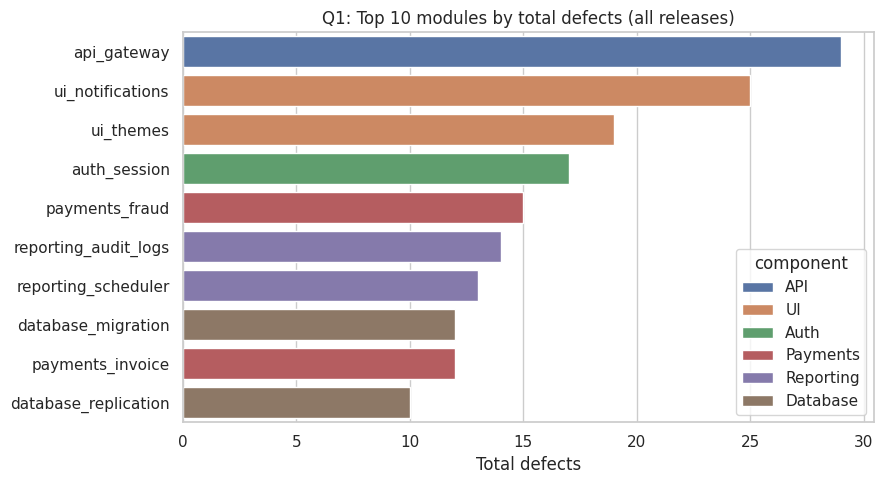

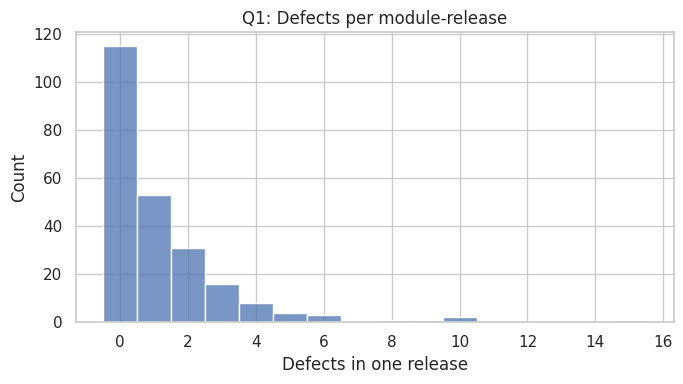

           sum  mean
component           
UI          70  1.75
Payments    55  1.38
API         50  1.25
Reporting   43  1.08
Database    36  1.03
Auth        31  0.78
Top 10 modules share of all defects: 58.2%


In [25]:
top10 = module_summary.head(10)
plt.figure(figsize=(9, 5))
sns.barplot(data=top10, y='module', x='total_defects', hue='component', dodge=False)
plt.title('Q1: Top 10 modules by total defects (all releases)')
plt.xlabel('Total defects'); plt.ylabel('')
save('q1_top10_modules')

plt.figure(figsize=(7, 4))
sns.histplot(df['total_defects'], discrete=True)
plt.title('Q1: Defects per module-release'); plt.xlabel('Defects in one release')
save('q1_defect_distribution')

print(df.groupby('component')['total_defects'].agg(['sum', 'mean']).round(2).sort_values('sum', ascending=False))
print('Top 10 modules share of all defects: %.1f%%' % (top10['total_defects'].sum() / df['total_defects'].sum() * 100))

Cell 3: Correlation of each metric with defects (the core business question)

,pearson,spearman
churn,0.65,0.41
changed_lines,0.65,0.41
coupling,0.34,0.40
complexity,0.35,0.40
contributors,0.51,0.38
commit_count,0.61,0.36
size,0.24,0.11
test_coverage,-0.39,-0.39


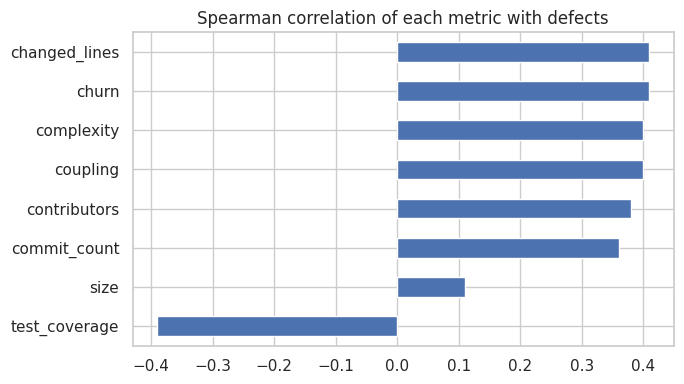

In [26]:
metric_list = ['complexity', 'coupling', 'churn', 'test_coverage', 'contributors',
               'commit_count', 'changed_lines', 'size']
corr = pd.DataFrame({
    'pearson':  [df[c].corr(df['total_defects']) for c in metric_list],
    'spearman': [df[c].corr(df['total_defects'], method='spearman') for c in metric_list]
}, index=metric_list).round(2).sort_values('spearman', ascending=False)
display(corr)

plt.figure(figsize=(7, 4))
corr['spearman'].sort_values().plot(kind='barh')
plt.title('Spearman correlation of each metric with defects')
save('corr_metrics_vs_defects')

Cell 4: Q2 and Q3, complexity and churn

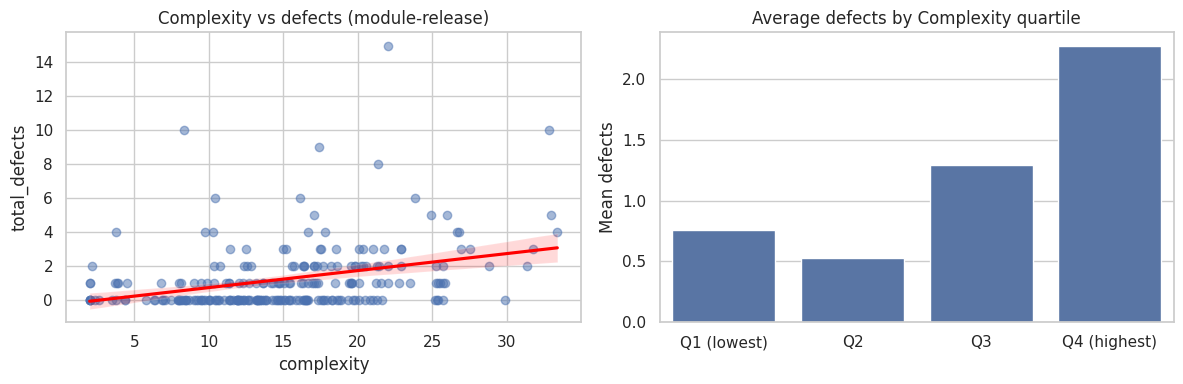

,mean,median,count
complexity,,,
Q1 (lowest),0.76,0.0,59
Q2,0.53,0.0,59
Q3,1.29,1.0,58
Q4 (highest),2.27,2.0,59


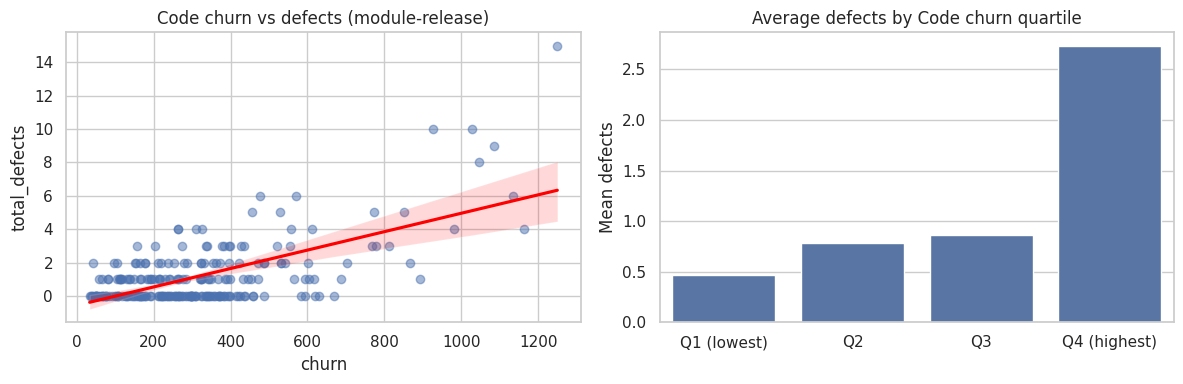

,mean,median,count
churn,,,
Q1 (lowest),0.47,0.0,59
Q2,0.78,0.0,59
Q3,0.86,0.0,58
Q4 (highest),2.73,2.0,59


In [27]:
def relation(col, label, name):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.regplot(data=df, x=col, y='total_defects', scatter_kws={'alpha': 0.5},
                line_kws={'color': 'red'}, ax=ax[0])
    ax[0].set_title(f'{label} vs defects (module-release)')
    band = pd.qcut(df[col], 4, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])
    summary = df.groupby(band, observed=True)['total_defects'].agg(['mean', 'median', 'count']).round(2)
    sns.barplot(x=summary.index.astype(str), y=summary['mean'], ax=ax[1])
    ax[1].set_title(f'Average defects by {label} quartile'); ax[1].set_xlabel(''); ax[1].set_ylabel('Mean defects')
    save(name)
    display(summary)

relation('complexity', 'Complexity', 'q2_complexity')
relation('churn', 'Code churn', 'q3_churn')

In [28]:
miss = df.isna().sum()
print(miss[miss > 0])

complexity_raw    14
dtype: int64


# Phase 4b: Questions 4 to 6

Cell 1: Q4, how does test coverage differ?

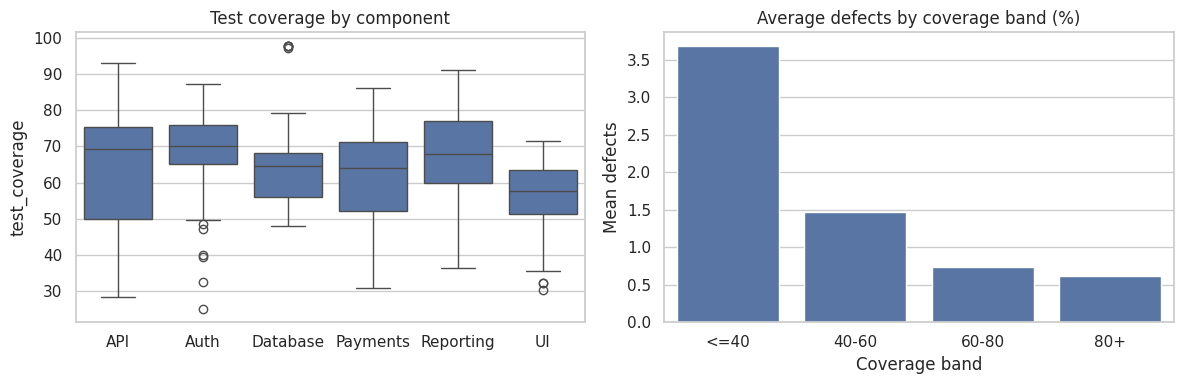

,mean,median,count
test_coverage,,,
<=40,3.68,2.0,22
40-60,1.47,1.0,68
60-80,0.73,0.0,124
80+,0.62,0.0,21


component
UI           55.6
Payments     61.1
API          63.8
Reporting    66.5
Auth         66.7
Database     66.9
Name: test_coverage, dtype: float64
Avg coverage, top-10 defect modules: 49.2 | other modules: 67.2


In [29]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='component', y='test_coverage', ax=ax[0])
ax[0].set_title('Test coverage by component'); ax[0].set_xlabel('')
bands = pd.cut(df['test_coverage'], bins=[0, 40, 60, 80, 100], labels=['<=40', '40-60', '60-80', '80+'])
cov = df.groupby(bands, observed=True)['total_defects'].agg(['mean', 'median', 'count']).round(2)
sns.barplot(x=cov.index.astype(str), y=cov['mean'], ax=ax[1])
ax[1].set_title('Average defects by coverage band (%)'); ax[1].set_xlabel('Coverage band'); ax[1].set_ylabel('Mean defects')
save('q4_coverage')

display(cov)
print(df.groupby('component')['test_coverage'].mean().round(1).sort_values())
print('Avg coverage, top-10 defect modules: %.1f | other modules: %.1f' % (
    module_summary.head(10)['avg_coverage'].mean(), module_summary.iloc[10:]['avg_coverage'].mean()))

Cell 2: Q5, which components show repeated defects?

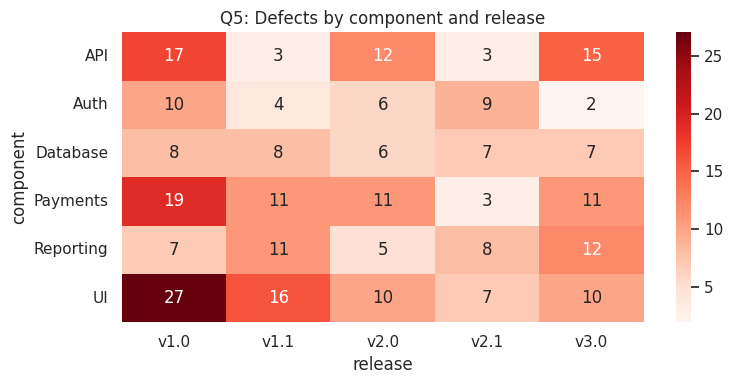

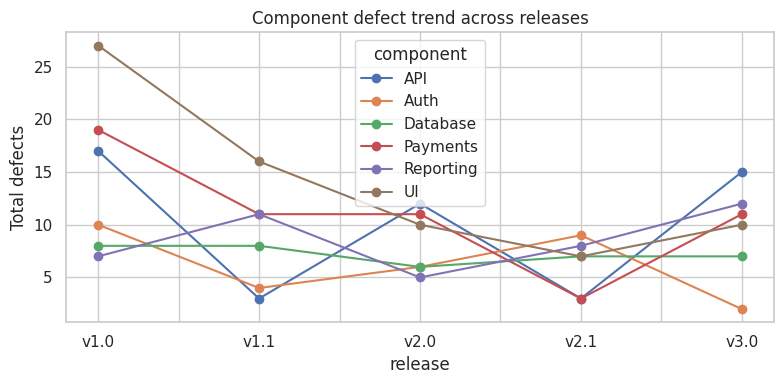

release,v1.0,v1.1,v2.0,v2.1,v3.0
component,,,,,
API,17,3,12,3,15
Auth,10,4,6,9,2
Database,8,8,6,7,7
Payments,19,11,11,3,11
Reporting,7,11,5,8,12
UI,27,16,10,7,10


Modules by number of releases with defects:
releases_with_defects
0     6
1     6
2    13
3     6
4    10
5     6
Name: count, dtype: int64
repeat_defect_flag (2+ releases) covers 35 of 47 modules
           sum  count
component            
API          2      8
Auth         1      8
Database     3      7
Payments     3      8
Reporting    3      8
UI           4      8


In [30]:
heat = df.pivot_table(index='component', columns='release', values='total_defects', aggfunc='sum')
plt.figure(figsize=(8, 4))
sns.heatmap(heat, annot=True, fmt='g', cmap='Reds')
plt.title('Q5: Defects by component and release')
save('q5_component_release_heatmap')

heat.T.plot(marker='o', figsize=(8, 4))
plt.title('Component defect trend across releases'); plt.ylabel('Total defects')
save('q5_component_trend')

display(heat)
print('Modules by number of releases with defects:')
print(module_summary['releases_with_defects'].value_counts().sort_index())
print('repeat_defect_flag (2+ releases) covers', df.groupby('module')['repeat_defect_flag'].first().sum(), 'of 47 modules')

module_summary['repeat_4plus'] = module_summary['releases_with_defects'] >= 4
print(module_summary.groupby('component')['repeat_4plus'].agg(['sum', 'count']))

Cell 3: Q6, does contributor count relate to defect frequency?

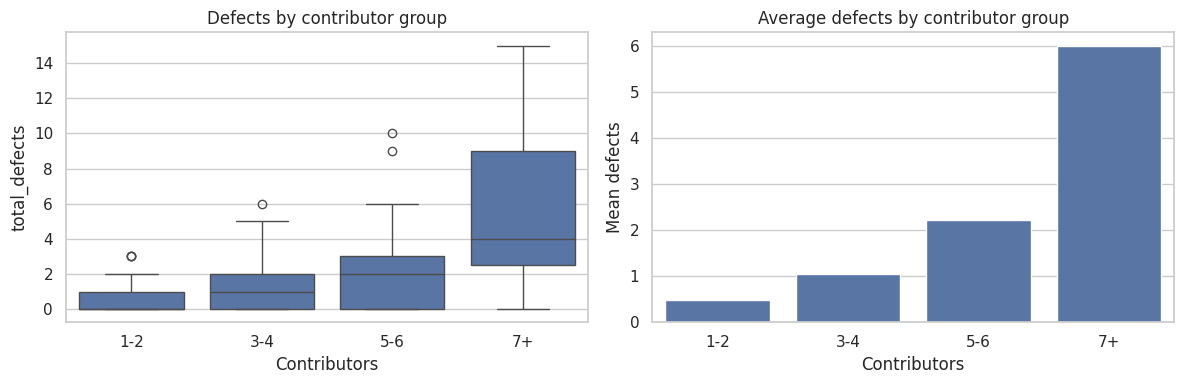

,mean,median,count
contributors,,,
1-2,0.49,0.0,79
3-4,1.05,1.0,108
5-6,2.22,2.0,41
7+,6.00,4.0,7


               contributors  commit_count  churn  total_defects
contributors           1.00          0.88   0.79           0.51
commit_count           0.88          1.00   0.89           0.61
churn                  0.79          0.89   1.00           0.65
total_defects          0.51          0.61   0.65           1.00


In [31]:
groups = pd.cut(df['contributors'], bins=[0, 2, 4, 6, 20], labels=['1-2', '3-4', '5-6', '7+'])
con = df.groupby(groups, observed=True)['total_defects'].agg(['mean', 'median', 'count']).round(2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=groups, y=df['total_defects'], ax=ax[0])
ax[0].set_title('Defects by contributor group'); ax[0].set_xlabel('Contributors')
sns.barplot(x=con.index.astype(str), y=con['mean'], ax=ax[1])
ax[1].set_title('Average defects by contributor group'); ax[1].set_xlabel('Contributors'); ax[1].set_ylabel('Mean defects')
save('q6_contributors')

display(con)
print(df[['contributors', 'commit_count', 'churn', 'total_defects']].corr().round(2))

Cell 4: Correlation heatmap and summary statistics

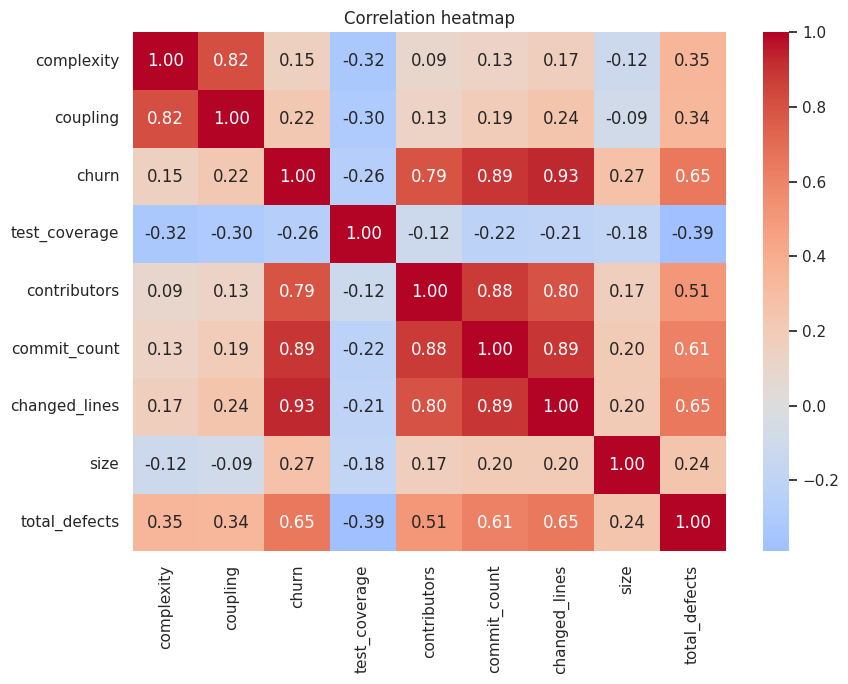

,complexity,coupling,churn,test_coverage,contributors,commit_count,changed_lines,size,total_defects
complexity,1.00,0.82,0.15,-0.32,0.09,0.13,0.17,-0.12,0.35
coupling,0.82,1.00,0.22,-0.30,0.13,0.19,0.24,-0.09,0.34
churn,0.15,0.22,1.00,-0.26,0.79,0.89,0.93,0.27,0.65
test_coverage,-0.32,-0.30,-0.26,1.00,-0.12,-0.22,-0.21,-0.18,-0.39
contributors,0.09,0.13,0.79,-0.12,1.00,0.88,0.80,0.17,0.51
commit_count,0.13,0.19,0.89,-0.22,0.88,1.00,0.89,0.20,0.61
changed_lines,0.17,0.24,0.93,-0.21,0.80,0.89,1.00,0.20,0.65
size,-0.12,-0.09,0.27,-0.18,0.17,0.20,0.20,1.00,0.24
total_defects,0.35,0.34,0.65,-0.39,0.51,0.61,0.65,0.24,1.00


,complexity,coupling,churn,test_coverage,contributors,commit_count,changed_lines,size,total_defects
count,235.00,235.00,235.00,235.00,235.00,235.00,235.00,235.00,235.00
mean,15.07,10.69,322.53,63.35,3.31,10.89,455.46,2275.26,1.21
std,6.68,3.61,226.80,14.97,1.57,8.91,333.79,1120.33,1.94
min,2.00,1.00,33.70,24.90,1.00,1.00,46.00,619.00,0.00
25%,10.45,8.36,165.20,54.70,2.00,5.00,230.50,1565.00,0.00
50%,14.96,10.57,282.00,65.40,3.00,10.00,384.00,2143.00,1.00
75%,19.53,13.11,397.35,73.15,4.00,14.00,569.50,2891.00,2.00
max,33.40,21.88,1249.40,98.00,9.00,59.00,1964.00,7222.00,15.00


In [32]:
cols = ['complexity', 'coupling', 'churn', 'test_coverage', 'contributors',
        'commit_count', 'changed_lines', 'size', 'total_defects']
cm = df[cols].corr().round(2)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap')
save('correlation_heatmap')
display(cm)
display(df[cols].describe().round(2))

# Phase 5a: Feature selection

Cell 1: Housekeeping (stricter repeat flag, drop complexity_raw)

In [33]:
rwd = df.groupby('module')['total_defects'].transform(lambda s: (s > 0).sum())
df['repeat_defect_flag'] = (rwd >= 4).astype(int)
print('repeat-defect modules:', df.groupby('module')['repeat_defect_flag'].first().sum())   # expect 16

df = df.drop(columns=['complexity_raw'])
print(df.shape, '| missing cells:', int(df.isna().sum().sum()))                              # expect (235, 41) and 0

module_summary['repeat_defect_module'] = (module_summary['releases_with_defects'] >= 4).astype(int)
df.to_csv(f'{CLEAN}/ch28_clean_module_release.csv', index=False)
module_summary.to_csv(f'{CLEAN}/ch28_module_summary.csv', index=False)

repeat-defect modules: 16
(235, 41) | missing cells: 0


Cell 2: Correlation filter (drop one of any pair above 0.85)

In [34]:
num_feats = ['complexity', 'coupling', 'churn', 'changed_lines', 'commit_count', 'contributors',
             'test_coverage', 'size', 'churn_per_commit', 'lines_per_contributor',
             'commits_per_contributor', 'release_index']

cm = df[num_feats].corr().abs()
target_corr = df[num_feats].corrwith(df['total_defects']).abs()

dropped = set()
for i, a in enumerate(num_feats):
    for b in num_feats[i + 1:]:
        if a in dropped or b in dropped:
            continue
        if cm.loc[a, b] > 0.85:
            drop = a if target_corr[a] < target_corr[b] else b
            dropped.add(drop)
            print(f'{a} vs {b}: corr {cm.loc[a, b]:.2f} -> drop {drop}')

kept_num = [f for f in num_feats if f not in dropped]
dummy_cols = [c for c in df.columns if c.startswith(('comp_', 'lang_'))]
features = kept_num + dummy_cols
print('\nKept numeric:', kept_num)
print('Total features going into the model:', len(features))

churn vs changed_lines: corr 0.93 -> drop churn
changed_lines vs commit_count: corr 0.89 -> drop commit_count

Kept numeric: ['complexity', 'coupling', 'changed_lines', 'contributors', 'test_coverage', 'size', 'churn_per_commit', 'lines_per_contributor', 'commits_per_contributor', 'release_index']
Total features going into the model: 20


Cell 3: Feature importance with a Random Forest

,rf_importance,permutation_importance
changed_lines,0.479,0.507
coupling,0.096,0.037
test_coverage,0.090,0.036
commits_per_contributor,0.070,0.000
release_index,0.056,0.009
complexity,0.052,0.050
contributors,0.051,-0.017
size,0.037,-0.010
lines_per_contributor,0.029,0.003
churn_per_commit,0.024,-0.006


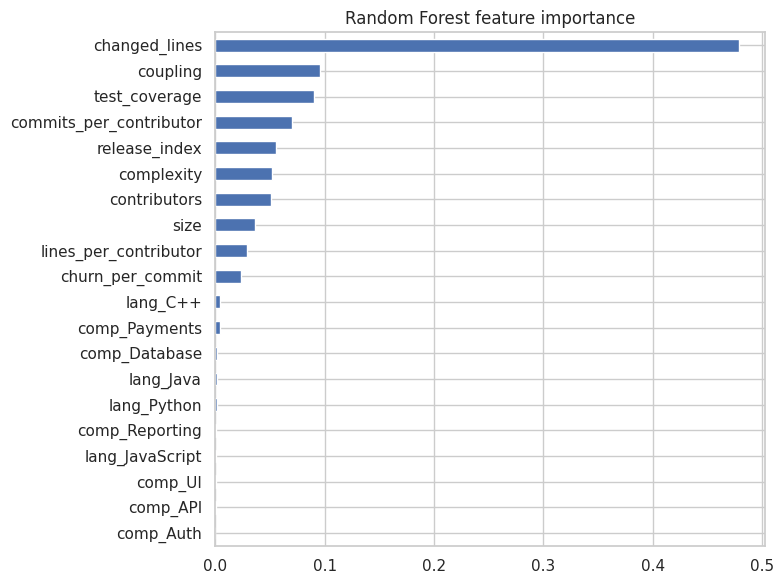

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

X = df[features]
y = df['total_defects']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)
rf.fit(X_train, y_train)

imp = pd.Series(rf.feature_importances_, index=features)
perm = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=42)
perm_s = pd.Series(perm.importances_mean, index=features)

result = pd.DataFrame({'rf_importance': imp, 'permutation_importance': perm_s}).round(3)
display(result.sort_values('rf_importance', ascending=False))

plt.figure(figsize=(8, 6))
imp.sort_values().plot(kind='barh')
plt.title('Random Forest feature importance')
save('feature_importance')

# Phase 5b: Train and compare models

Cell 1: Feature sets

In [36]:
core = ['churn', 'complexity', 'coupling', 'test_coverage']
dummy_cols = [c for c in df.columns if c.startswith(('comp_', 'lang_'))]
extended = core + ['contributors', 'size', 'release_index'] + dummy_cols
y = df['total_defects']
print(len(core), 'core features |', len(extended), 'extended features')

4 core features | 17 extended features


Cell 2: Train and test (80/20 split)

In [37]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

idx_train, idx_test = train_test_split(df.index, test_size=0.2, random_state=42)
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

def rf():
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42)

experiments = {
    'Linear Regression | core 4':    (LinearRegression(), core),
    'Linear Regression | extended':  (LinearRegression(), extended),
    'Random Forest | core 4':        (rf(), core),
    'Random Forest | extended':      (rf(), extended),
}

rows, preds = [], {}
base = np.full(len(y_test), y_train.mean())          # always predict the training mean
rows.append({'model': 'Baseline: predict the mean',
             'RMSE': np.sqrt(mean_squared_error(y_test, base)),
             'MAE': mean_absolute_error(y_test, base), 'R2': r2_score(y_test, base)})

for name, (model, cols) in experiments.items():
    model.fit(df.loc[idx_train, cols], y_train)
    p = model.predict(df.loc[idx_test, cols])
    preds[name] = p
    rows.append({'model': name, 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'MAE': mean_absolute_error(y_test, p), 'R2': r2_score(y_test, p)})

results = pd.DataFrame(rows).round(3).sort_values('RMSE')
display(results)

,model,RMSE,MAE,R2
1,Linear Regression | core 4,1.258,0.922,0.492
3,Random Forest | core 4,1.340,0.874,0.424
4,Random Forest | extended,1.371,0.905,0.396
2,Linear Regression | extended,1.372,1.024,0.396
0,Baseline: predict the mean,1.810,1.308,-0.051


Cell 3: Stricter check by module

In [38]:
from sklearn.model_selection import GroupKFold, cross_validate

gkf = GroupKFold(n_splits=5)
cv_rows = []
for name, (model, cols) in experiments.items():
    cv = cross_validate(model, df[cols], y, groups=df['module'], cv=gkf,
                        scoring=['neg_root_mean_squared_error', 'r2'])
    cv_rows.append({'model': name,
                    'CV_RMSE': -cv['test_neg_root_mean_squared_error'].mean(),
                    'CV_R2': cv['test_r2'].mean()})
display(pd.DataFrame(cv_rows).round(3).sort_values('CV_RMSE'))

,model,CV_RMSE,CV_R2
3,Random Forest | extended,1.291,0.362
2,Random Forest | core 4,1.305,0.351
0,Linear Regression | core 4,1.382,0.320
1,Linear Regression | extended,1.458,0.248


Cell 4: Actual vs predicted chart

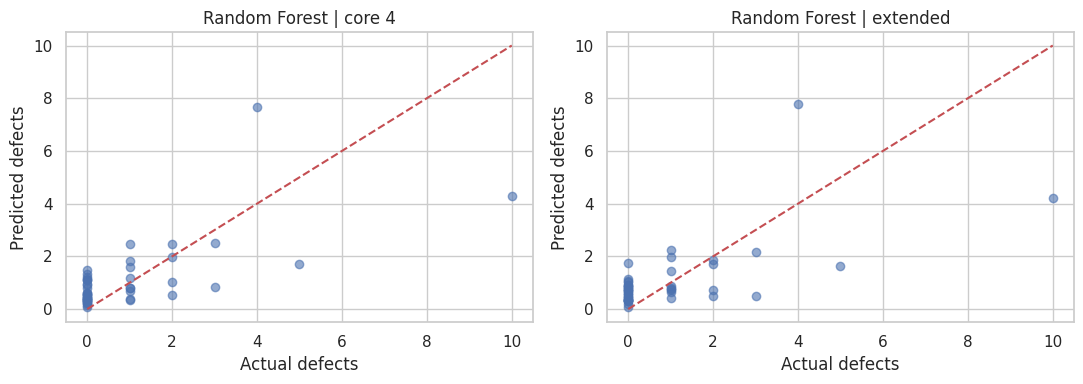

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, name in zip(ax, ['Random Forest | core 4', 'Random Forest | extended']):
    a.scatter(y_test, preds[name], alpha=0.6)
    a.plot([0, y_test.max()], [0, y_test.max()], 'r--')
    a.set_title(name); a.set_xlabel('Actual defects'); a.set_ylabel('Predicted defects')
save('actual_vs_predicted')

# Phase 5c: Classifier and risk-ranking prototype

Cell 1: Classifier for high-defect rows

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, GroupKFold
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced', random_state=42)
yc = df['high_defect']
proba = cross_val_predict(clf, df[core], yc, groups=df['module'],
                          cv=GroupKFold(n_splits=5), method='predict_proba')[:, 1]

rows = []
for t in [0.3, 0.4, 0.5]:
    pred = (proba >= t).astype(int)
    rows.append({'threshold': t, 'precision': precision_score(yc, pred), 'recall': recall_score(yc, pred),
                 'F1': f1_score(yc, pred)})
display(pd.DataFrame(rows).round(3))
print('ROC-AUC:', round(roc_auc_score(yc, proba), 3))
print('Confusion matrix at 0.4 (rows = actual 0/1, columns = predicted 0/1):')
print(confusion_matrix(yc, (proba >= 0.4).astype(int)))

,threshold,precision,recall,F1
0,0.3,0.403,0.750,0.524
1,0.4,0.413,0.528,0.463
2,0.5,0.515,0.472,0.493


ROC-AUC: 0.797
Confusion matrix at 0.4 (rows = actual 0/1, columns = predicted 0/1):
[[172  27]
 [ 17  19]]


Cell 2: Module risk ranking (the prototype)

In [41]:
oof = cross_val_predict(rf(), df[core], df['total_defects'], groups=df['module'], cv=GroupKFold(n_splits=5))
scored = df[['module', 'component', 'release', 'release_index', 'total_defects',
             'churn', 'complexity', 'test_coverage']].copy()
scored['predicted_defects'] = oof

from scipy.stats import spearmanr
print('Rank agreement, predicted vs actual (all rows), Spearman:', round(spearmanr(scored['predicted_defects'], scored['total_defects'])[0], 3))

latest = scored[scored['release_index'] == scored['release_index'].max()].copy()
latest = latest.merge(module_summary[['module', 'releases_with_defects']], on='module')
churn_high = latest['churn'] > df['churn'].quantile(0.75)
cov_low = latest['test_coverage'] < 60
latest['action'] = np.select([churn_high & cov_low, churn_high, cov_low],
                             ['Code review + more tests', 'Priority code review', 'Add tests'], default='Monitor')

priority = (latest.rename(columns={'total_defects': 'actual_defects'})
            .sort_values('predicted_defects', ascending=False)
            [['module', 'component', 'predicted_defects', 'actual_defects', 'releases_with_defects',
              'churn', 'complexity', 'test_coverage', 'action']].round(2).reset_index(drop=True))
display(priority.head(10))
print(priority['action'].value_counts())
priority.to_csv(f'{OUT}/module_priority_list.csv', index=False)

Rank agreement, predicted vs actual (all rows), Spearman: 0.556


,module,component,predicted_defects,actual_defects,releases_with_defects,churn,complexity,test_coverage,action
0,api_docs,API,8.55,4,1,1161.8,10.27,87.40,Priority code review
1,payments_wallet,Payments,4.54,1,3,563.7,25.49,36.90,Code review + more tests
2,payments_fraud,Payments,3.19,1,4,454.2,20.06,30.70,Code review + more tests
3,ui_themes,UI,3.00,5,4,529.0,32.95,57.60,Code review + more tests
4,payments_gateway,Payments,2.11,1,4,326.7,22.80,65.40,Monitor
5,reporting_audit_logs,Reporting,2.00,5,5,773.4,24.92,62.40,Priority code review
6,reporting_scheduler,Reporting,1.76,4,5,262.5,33.40,41.05,Add tests
7,api_gateway,API,1.75,5,5,455.5,17.03,41.10,Code review + more tests
8,api_versioning,API,1.75,1,3,594.2,15.06,59.50,Code review + more tests
9,api_webhooks,API,1.62,0,4,100.2,13.69,29.50,Add tests


action
Monitor                     24
Add tests                    9
Code review + more tests     8
Priority code review         6
Name: count, dtype: int64


Cell 3: Prototype chart

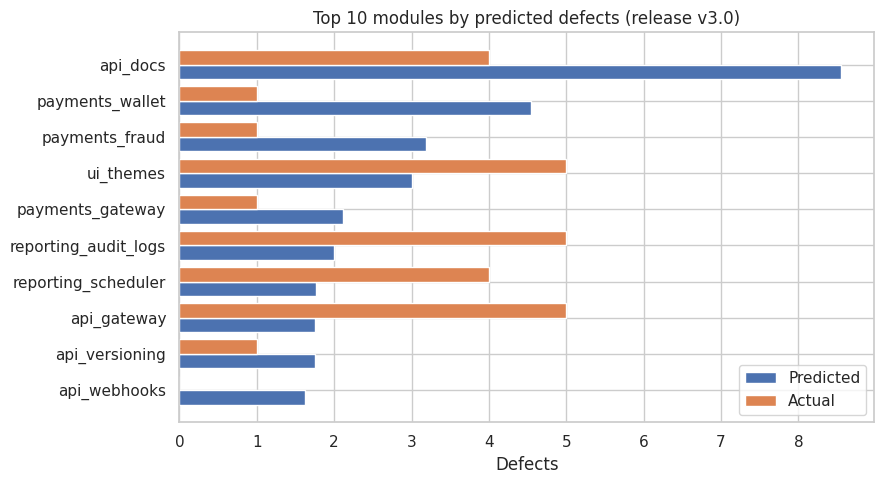

In [42]:
top = priority.head(10).iloc[::-1]
ypos = np.arange(len(top)); h = 0.4
plt.figure(figsize=(9, 5))
plt.barh(ypos - h / 2, top['predicted_defects'], height=h, label='Predicted')
plt.barh(ypos + h / 2, top['actual_defects'], height=h, label='Actual')
plt.yticks(ypos, top['module'])
plt.title(f'Top 10 modules by predicted defects (release {latest["release"].iloc[0]})')
plt.xlabel('Defects'); plt.legend()
save('risk_ranking_top10')

builds the tiered list for all 47 modules

In [43]:
final = priority.merge(module_summary[['module', 'repeat_defect_module', 'total_defects', 'avg_risk_score']],
                       on='module', how='left')
final = final.rename(columns={'total_defects': 'total_defects_all_releases'})
final['priority_tier'] = np.select(
    [(final['repeat_defect_module'] == 1) & (final['action'] != 'Monitor'),
     (final['action'] != 'Monitor') | (final['predicted_defects'] >= 2)],
    ['Tier 1: fix first', 'Tier 2: watch closely'], default='Tier 3: monitor')
final = final.sort_values(['priority_tier', 'predicted_defects'], ascending=[True, False]).reset_index(drop=True)

display(final['priority_tier'].value_counts())
display(final[final['priority_tier'].str.startswith('Tier 1')]
        [['module', 'component', 'releases_with_defects', 'churn', 'test_coverage', 'predicted_defects', 'action']])
final.to_csv(f'{CLEAN}/ch28_module_priority_tiers.csv', index=False)
print('saved', final.shape)

,count
priority_tier,
Tier 3: monitor,23
Tier 2: watch closely,13
Tier 1: fix first,11


,module,component,releases_with_defects,churn,test_coverage,predicted_defects,action
0,payments_fraud,Payments,4,454.2,30.70,3.19,Code review + more tests
1,ui_themes,UI,4,529.0,57.60,3.00,Code review + more tests
2,reporting_audit_logs,Reporting,5,773.4,62.40,2.00,Priority code review
3,reporting_scheduler,Reporting,5,262.5,41.05,1.76,Add tests
4,api_gateway,API,5,455.5,41.10,1.75,Code review + more tests
5,api_webhooks,API,4,100.2,29.50,1.62,Add tests
6,reporting_export,Reporting,4,399.0,61.80,1.54,Priority code review
7,ui_notifications,UI,4,593.4,35.40,1.37,Code review + more tests
8,auth_session,Auth,5,167.9,47.20,1.07,Add tests
9,ui_charts,UI,4,214.1,58.90,0.79,Add tests


saved (47, 13)
